# Education HBO, WO in Amsterdam (2010-2024)

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

In [2]:
file_path = "Education levels.xlsx"

education = pd.read_excel(
    file_path,
    sheet_name="data",
    engine="openpyxl"
)

metadata = pd.read_excel(
    file_path,
    sheet_name="metadata",
    engine="openpyxl"
)

education.head()

,Year,Geography,Code,Name,"education hbo, wo (%)"
0,2021,ggwgebieden,GA02,Centrum-Oost,62
1,2021,ggwgebieden,GK12,"Buitenveldert, Zuidas",54
2,2021,ggwgebieden,GK11,Oud-Zuid,66
3,2021,ggwgebieden,GF10,Slotervaart,41
4,2021,ggwgebieden,GA01,Centrum-West,62


In [5]:
education_df = education[
    ["Year", "Name", "education hbo, wo (%)"]]

print("Number of observations:", len(education_df))
print("Number of GGW areas:", education_df["Name"].nunique())
print("Number of years:", education_df["Year"].nunique())
print("First year:", education_df["Year"].min())
print("Most recent year:", education_df["Year"].max())

print("\nData types:")
print(education_df.dtypes)

Number of observations: 356
Number of GGW areas: 25
Number of years: 15
First year: 2010
Most recent year: 2024

Data types:
Year                     int64
Name                       str
education hbo, wo (%)    int64
dtype: object


This verifies and confirms the correct number of areas (25) and the period of the dataset (2010-2024). This also supports the description of the relevant variables: "Year", "Name", and "Education". 

# Missing data
We will investigate all possible combinations of years and areas to identify the missing observations. 

In [7]:
all_years = range(2010, 2025)
all_areas = education_df["Name"].unique()

complete_index = pd.MultiIndex.from_product(
    [all_years, all_areas],
    names=["Year", "Name"]
)

# Add absent combinations as missing values
complete_df = (
    education_df
    .set_index(["Year", "Name"])
    .reindex(complete_index)
    .reset_index()
)

# Select missing observations
missing_data = complete_df[
    complete_df["education hbo, wo (%)"].isna()
]

print("Number of missing year-area observations:", len(missing_data))
print()

print(
    missing_data
    .groupby("Name")["Year"]
    .apply(list)
)

Number of missing year-area observations: 19

Name
Bijlmer-West                         [2010, 2011, 2012, 2013, 2014]
Sloterdijk Nieuw-West    [2010, 2011, 2012, 2013, 2014, 2015, 2016]
Weesp, Driemond          [2010, 2011, 2012, 2013, 2014, 2015, 2016]
Name: Year, dtype: object


We also want to confirm that all 25 GGW areas contain an education value for 2024 because it is the most recent year available. The following code will check this and for any missing values. 

In [8]:
education_2024 = education_df[
    education_df["Year"] == 2024
].copy()

print("Number of GGW areas in 2024:", education_2024["Name"].nunique())
print(
    "Missing education values in 2024:",
    education_2024["education hbo, wo (%)"].isna().sum()
)

Number of GGW areas in 2024: 25
Missing education values in 2024: 0


# Checking for any outliers 
Potential outliers are examined using the interquartile range (IQR) method. An observation is considered a potential outlier if it falls below
Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR. 

In [9]:
Q1 = education_2024["education hbo, wo (%)"].quantile(0.25)
Q3 = education_2024["education hbo, wo (%)"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = education_2024[
    (education_2024["education hbo, wo (%)"] < lower_bound) |
    (education_2024["education hbo, wo (%)"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of potential outliers:", len(outliers))

Lower bound: 3.0
Upper bound: 91.0
Number of potential outliers: 0


Therefore, we can confirm that there are no outliers for the 2024 values. 

# Data visualization 
The following graph compares the % of residents aged 15–74 with a completed HBO or WO education across the 25 Amsterdam GGW areas in 2024.

The horiztonal line represents the municipality's reported citywide Amsterdam value of 49%. This makes it possible to compare individual GGW areas with the citywide percentage.

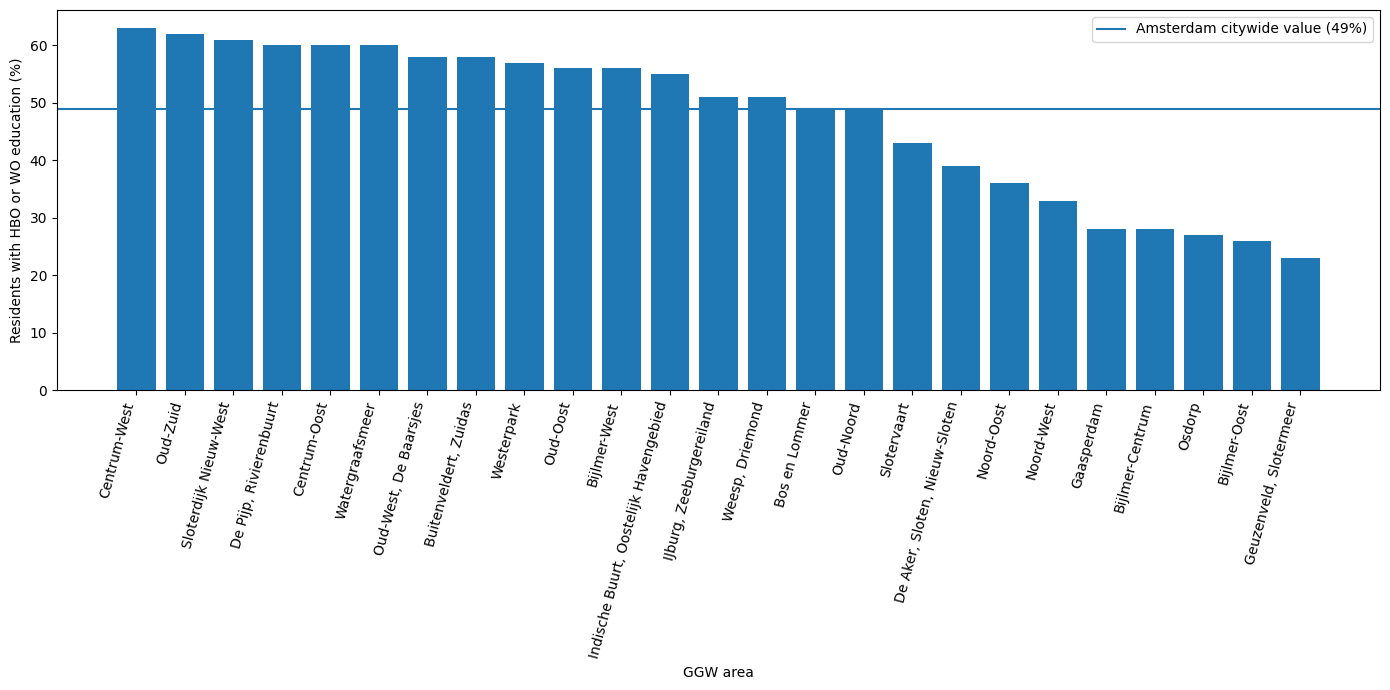

In [12]:
# Sort areas from lowest to highest education percentage
education_2024_sorted = education_2024.sort_values(
    by="education hbo, wo (%)",
    ascending=False
)

plt.figure(figsize=(14, 7))

plt.bar(
    education_2024_sorted["Name"],
    education_2024_sorted["education hbo, wo (%)"]
)

# Add the Amsterdam citywide percentage
plt.axhline(
    y=49,
    linestyle="-",
    label="Amsterdam citywide value (49%)"
)

plt.xlabel("GGW area")
plt.ylabel("Residents with HBO or WO education (%)")
plt.xticks(rotation=75, ha="right")

plt.legend()
plt.tight_layout()

plt.show()